# Netflix Data Analysis
## Auspify Technologies - Data Analysis Internship

### Project Overview
This project analyzes Netflix content using Python, Pandas, NumPy and Matplotlib.

## Task 1: Netflix Data Cleaning & Preparation

In [1]:
import numpy as np
import pandas as pd


In [2]:
df = pd.read_csv('Dataset.csv')

In [3]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
df.shape

(8790, 10)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 1.6 MB


In [6]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['type'].unique()

<ArrowStringArray>
['Movie', 'TV Show']
Length: 2, dtype: str

In [9]:
df['rating'].unique()

<ArrowStringArray>
[   'PG-13',    'TV-MA',    'TV-PG',    'TV-14',    'TV-Y7',     'TV-Y',
       'PG',     'TV-G',        'R',        'G',    'NC-17',       'NR',
 'TV-Y7-FV',       'UR']
Length: 14, dtype: str

In [10]:
df['country'].unique()

<ArrowStringArray>
[       'United States',               'France',               'Brazil',
       'United Kingdom',                'India',              'Germany',
             'Pakistan',            'Not Given',                'China',
         'South Africa',                'Japan',              'Nigeria',
                'Spain',          'Philippines',            'Australia',
            'Argentina',               'Canada',            'Hong Kong',
                'Italy',          'New Zealand',                'Egypt',
             'Colombia',               'Mexico',              'Belgium',
          'Switzerland',               'Taiwan',             'Bulgaria',
               'Poland',          'South Korea',         'Saudi Arabia',
             'Thailand',            'Indonesia',               'Kuwait',
             'Malaysia',              'Vietnam',              'Lebanon',
              'Romania',                'Syria', 'United Arab Emirates',
               'Sweden',        

In [11]:
df['date_added'].head(10)

0    9/25/2021
1    9/24/2021
2    9/24/2021
3    9/22/2021
4    9/24/2021
5    9/24/2021
6    9/24/2021
7     5/1/2021
8    9/23/2021
9     5/1/2021
Name: date_added, dtype: str

In [12]:
df['date_added'] = pd.to_datetime(df['date_added'])

In [13]:
df['date_added'].dtype

dtype('<M8[us]')

In [14]:
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month

In [15]:
df[['date_added', 'year_added', 'month_added']].head()

,date_added,year_added,month_added
0,2021-09-25,2021,9
1,2021-09-24,2021,9
2,2021-09-24,2021,9
3,2021-09-22,2021,9
4,2021-09-24,2021,9


In [16]:
df['country'] = df['country'].str.strip()

In [17]:
df['country'].unique()

<ArrowStringArray>
[       'United States',               'France',               'Brazil',
       'United Kingdom',                'India',              'Germany',
             'Pakistan',            'Not Given',                'China',
         'South Africa',                'Japan',              'Nigeria',
                'Spain',          'Philippines',            'Australia',
            'Argentina',               'Canada',            'Hong Kong',
                'Italy',          'New Zealand',                'Egypt',
             'Colombia',               'Mexico',              'Belgium',
          'Switzerland',               'Taiwan',             'Bulgaria',
               'Poland',          'South Korea',         'Saudi Arabia',
             'Thailand',            'Indonesia',               'Kuwait',
             'Malaysia',              'Vietnam',              'Lebanon',
              'Romania',                'Syria', 'United Arab Emirates',
               'Sweden',        

In [18]:
df['type'] = df['type'].str.strip()
df['rating'] = df['rating'].str.strip()

In [19]:
df['type'].unique()

<ArrowStringArray>
['Movie', 'TV Show']
Length: 2, dtype: str

In [20]:
df['rating'].unique()

<ArrowStringArray>
[   'PG-13',    'TV-MA',    'TV-PG',    'TV-14',    'TV-Y7',     'TV-Y',
       'PG',     'TV-G',        'R',        'G',    'NC-17',       'NR',
 'TV-Y7-FV',       'UR']
Length: 14, dtype: str

In [21]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
year_added      0
month_added     0
dtype: int64
Duplicate Rows: 0


In [25]:
df.to_csv('Netflix_Cleaned.csv', index=False)

In [26]:
df.to_csv('Netflix_Cleaned.csv', index=False)

In [27]:
import os

os.path.exists('Netflix_Cleaned.csv')

True

## Task 2: Content Type Analysis Dashboard

### Objective
Analyze the distribution of Movies and TV Shows available on Netflix.

### Task Workflow
1. Load the cleaned dataset.
2. Calculate the total number of Movies and TV Shows.
3. Create visualizations for content distribution.
4. Compare content proportions.
5. Summarize key findings.

In [29]:
content_counts = df['type'].value_counts()

content_counts

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

In [30]:
total_content = content_counts.sum()

content_percentage = (content_counts / total_content) * 100

content_percentage

type
Movie      69.692833
TV Show    30.307167
Name: count, dtype: float64

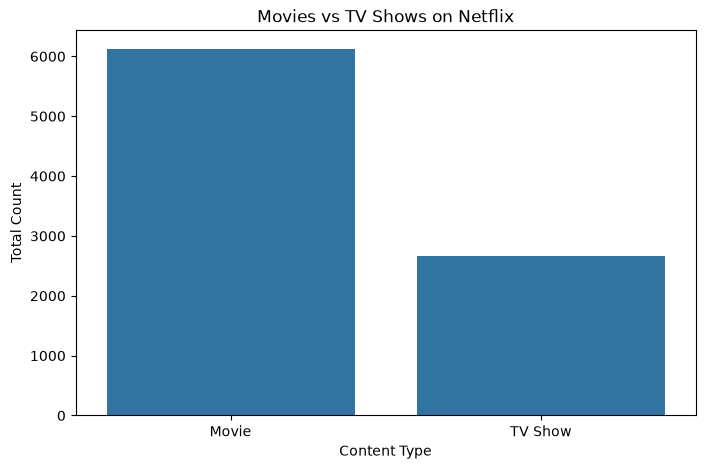

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(x=content_counts.index, y=content_counts.values)

plt.title('Movies vs TV Shows on Netflix')
plt.xlabel('Content Type')
plt.ylabel('Total Count')

plt.show()

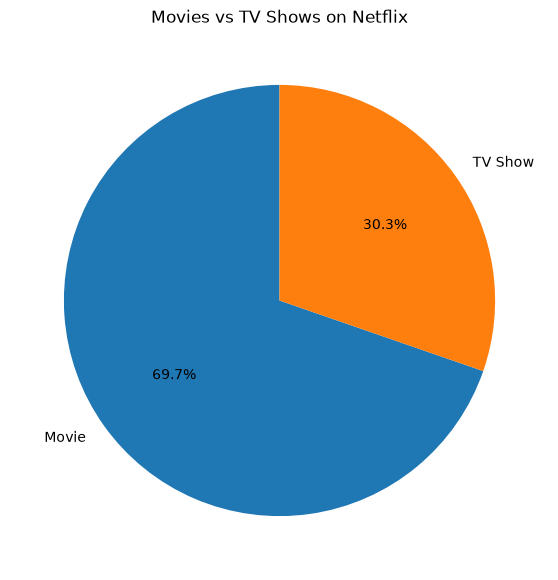

In [32]:
plt.figure(figsize=(7, 7))

plt.pie(
    content_counts.values,
    labels=content_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Movies vs TV Shows on Netflix')

plt.show()

## Key Findings

1. Total content available in the Netflix dataset is 8,790.
2. Movies account for approximately 69.7% of the total content.
3. TV Shows account for approximately 30.3% of the total content.
4. Movies are more available than TV Shows on Netflix.
5. Netflix has a larger collection of Movies compared to TV Shows.

## Task 3: Country-Wise Netflix Content Analysis

### Objective
Analyze Netflix content availability across different countries.

### Task Workflow
1. Extract and clean country information.
2. Calculate content count by country.
3. Identify top content-producing countries.
4. Create charts and rankings.
5. Generate business insights.



In [34]:
country_counts = df['country'].value_counts()

country_counts.head(10)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

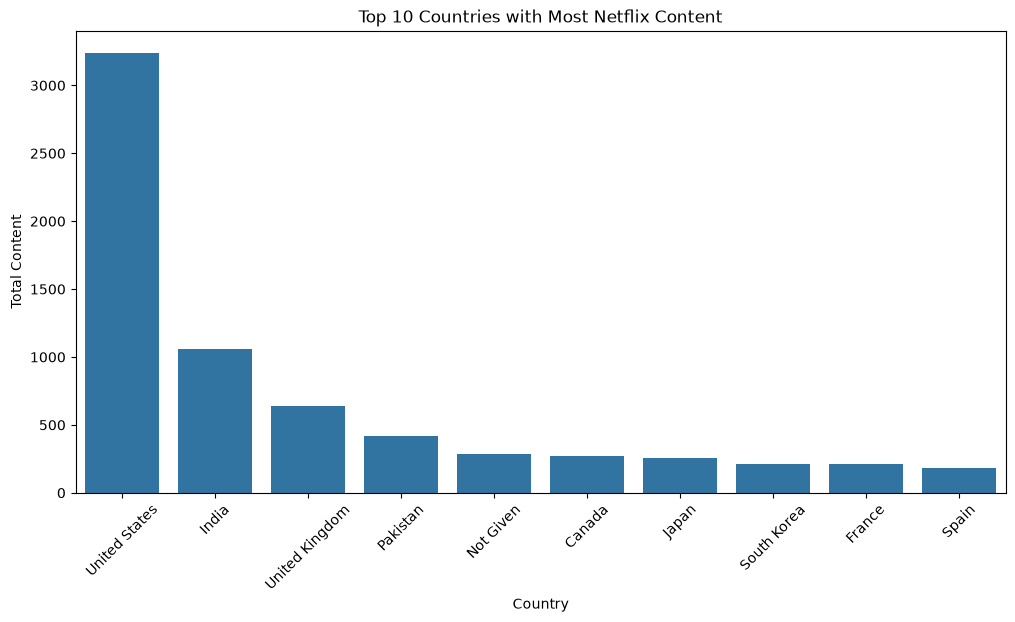

In [37]:
top_10_countries = country_counts.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_10_countries.index, y=top_10_countries.values)

plt.title('Top 10 Countries with Most Netflix Content')
plt.xlabel('Country')
plt.ylabel('Total Content')

plt.xticks(rotation=45)

plt.show()

## Key Findings

1. United States has the highest Netflix content with 3,240 titles.
2. India ranks second with 1,057 titles.
3. United Kingdom ranks third with 638 titles.
4. Pakistan has 421 titles and ranks fourth.
5. United States has significantly more content than other countries.
6. Country information is missing or not given for 287 records.

## Task 4: Trend Analysis by Release Year

### Objective
Analyze how Netflix content production has changed over time.

### Task Workflow
1. Organize content by release year.
2. Calculate yearly content releases.
3. Identify growth and decline trends.
4. Create trend visualizations.
5. Interpret business patterns.

In [38]:
yearly_content = df.groupby('release_year').size().sort_index()

yearly_content

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Length: 74, dtype: int64

In [39]:
yearly_content.sort_values(ascending=False).head(10)

release_year
2018    1146
2017    1030
2019    1030
2020     953
2016     901
2021     592
2015     555
2014     352
2013     286
2012     236
dtype: int64

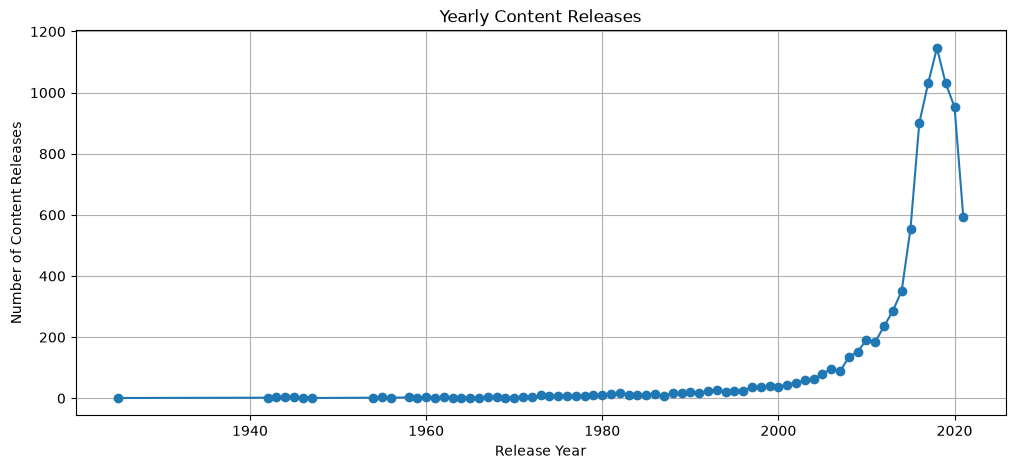

In [40]:
import matplotlib.pyplot as plt

yearly_content.sort_index().plot(
    kind='line',
    figsize=(12, 5),
    marker='o'
)

plt.title('Yearly Content Releases')
plt.xlabel('Release Year')
plt.ylabel('Number of Content Releases')
plt.grid()
plt.show()

In [41]:
yearly_growth = yearly_content.sort_index().pct_change() * 100

yearly_growth

release_year
1925           NaN
1942    100.000000
1943     50.000000
1944      0.000000
1945     33.333333
           ...    
2017     14.317425
2018     11.262136
2019    -10.122164
2020     -7.475728
2021    -37.880378
Length: 74, dtype: float64

In [42]:
print("Highest Growth Year:")
print(yearly_growth.idxmax())

print("Highest Decline Year:")
print(yearly_growth.idxmin())

Highest Growth Year:
1967
Highest Decline Year:
1961


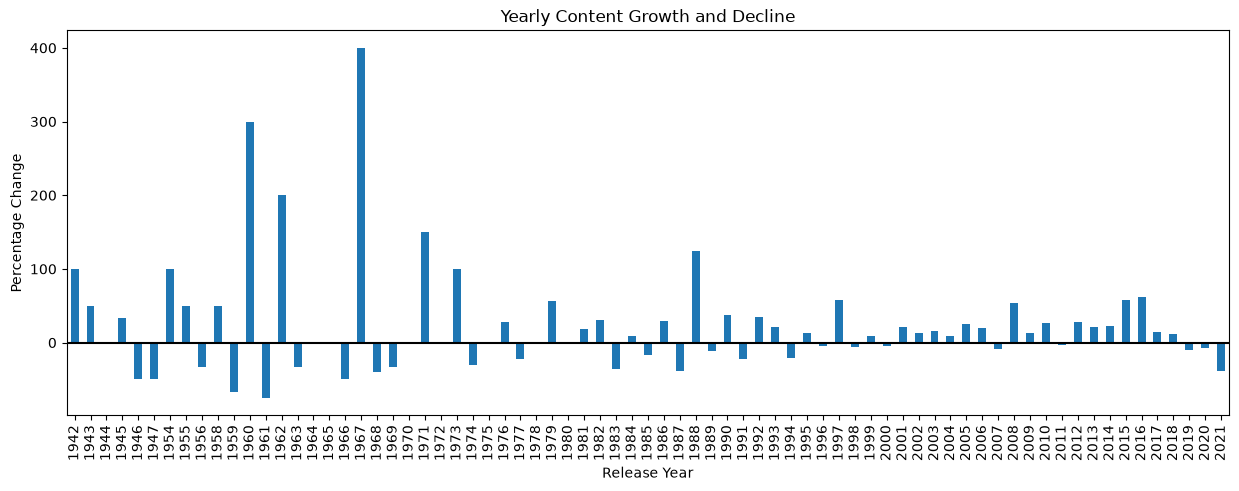

In [43]:
yearly_growth.dropna().plot(
    kind='bar',
    figsize=(15, 5)
)

plt.title('Yearly Content Growth and Decline')
plt.xlabel('Release Year')
plt.ylabel('Percentage Change')
plt.axhline(y=0, color='black')
plt.show()

### Business Insights

1. Netflix content releases increased over the years.
2. The highest number of content releases was recorded in 2018 with 1146 titles.
3. The highest growth percentage was observed in 1967.
4. The highest decline percentage was observed in 1961.
5. Content releases decreased from 2019 to 2021.
6. The analysis shows changes in Netflix content trends over time.

### Conclusion

The analysis shows that Netflix content releases increased significantly over time, reaching their peak in 2018. However, a decline was observed in the following years. This analysis helps understand historical content release patterns.